# K-Means Clustering with the Elbow Method

**Goal:** Group data points into clusters using K-Means, and use the **Elbow Method** (plotting **WCSS**) to pick the best number of clusters *K*.

**WCSS** (Within-Cluster Sum of Squares) = sum of squared distances between every point and the centroid of its cluster. Lower WCSS means tighter clusters.

**K-Means in 4 steps**
1. Pick *K* random points as initial centroids.
2. Assign every point to its nearest centroid.
3. Move each centroid to the mean of its assigned points.
4. Repeat steps 2–3 until the centroids stop moving.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## 1. Create a simple dataset (2 features, 300 points)
We generate 300 points around 4 hidden centres. The algorithm doesn't know this, so the Elbow Method has to discover it.

Dataset shape: (300, 2) -> 300 points, 2 features


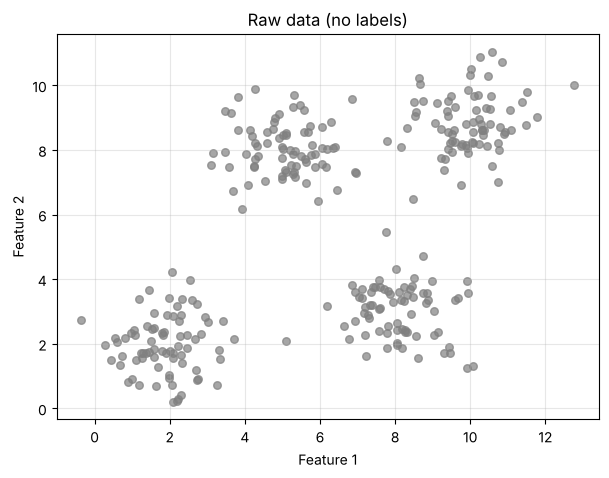

In [2]:
true_centres = np.array([[2, 2], [8, 3], [5, 8], [10, 9]])
points_per_cluster = 75   # 4 x 75 = 300 points

X = np.vstack([
    np.random.randn(points_per_cluster, 2) * 0.9 + centre
    for centre in true_centres
])

print("Dataset shape:", X.shape, "-> 300 points, 2 features")

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], s=30, color="gray", alpha=0.7)
plt.title("Raw data (no labels)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(alpha=0.3)
plt.show()

## 2. Implement K-Means from scratch

In [3]:
def kmeans(X, k, max_iters=100):
    # Step 1: choose k random data points as starting centroids
    centroids = X[np.random.choice(len(X), k, replace=False)]

    for _ in range(max_iters):
        # Step 2: distance from every point to every centroid, then pick the nearest
        distances = np.linalg.norm(X[:, None] - centroids[None, :], axis=2)
        labels = np.argmin(distances, axis=1)

        # Step 3: move each centroid to the mean of its points
        new_centroids = np.array([
            X[labels == i].mean(axis=0) if np.any(labels == i) else centroids[i]
            for i in range(k)
        ])

        # Step 4: stop if centroids did not move
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids

    # WCSS: sum of squared distances from each point to its own centroid
    wcss = np.sum((X - centroids[labels]) ** 2)
    return labels, centroids, wcss

## 3. Elbow Method: compute WCSS for K = 1 to 10
K-Means depends on random starting points, so for each *K* we run it 10 times and keep the run with the lowest WCSS.

In [4]:
k_values = range(1, 11)
wcss_values = []

for k in k_values:
    best_wcss = min(kmeans(X, k)[2] for _ in range(10))
    wcss_values.append(best_wcss)
    print(f"K = {k:2d}  ->  WCSS = {best_wcss:10.2f}")

K =  1  ->  WCSS =    5988.23


K =  2  ->  WCSS =    2825.90
K =  3  ->  WCSS =    1374.15
K =  4  ->  WCSS =     450.73
K =  5  ->  WCSS =     407.80
K =  6  ->  WCSS =     366.37
K =  7  ->  WCSS =     326.77
K =  8  ->  WCSS =     294.20


K =  9  ->  WCSS =     261.52


K = 10  ->  WCSS =     238.72


## 4. Elbow plot
The WCSS always decreases as *K* grows. The best *K* is at the **"elbow"**, where the curve stops dropping sharply and flattens out.

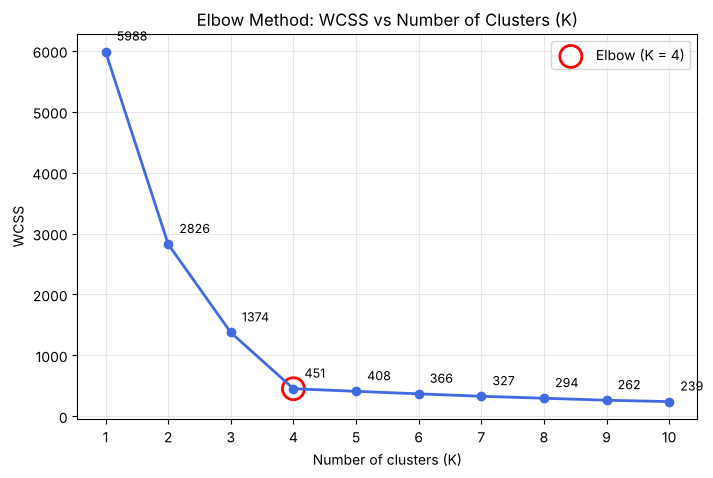

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), wcss_values, marker="o", color="royalblue", linewidth=2)

# Write the WCSS value next to every point
for k, w in zip(k_values, wcss_values):
    plt.annotate(f"{w:.0f}", (k, w), textcoords="offset points",
                 xytext=(8, 8), fontsize=9)

# Highlight the elbow
elbow_k = 4
plt.scatter(elbow_k, wcss_values[elbow_k - 1], s=250, facecolors="none",
            edgecolors="red", linewidths=2, label=f"Elbow (K = {elbow_k})")

plt.title("Elbow Method: WCSS vs Number of Clusters (K)")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Reading the plot:** WCSS falls steeply from K = 1 to K = 4, then the improvement becomes small. So the elbow is at **K = 4**, which matches how we generated the data.

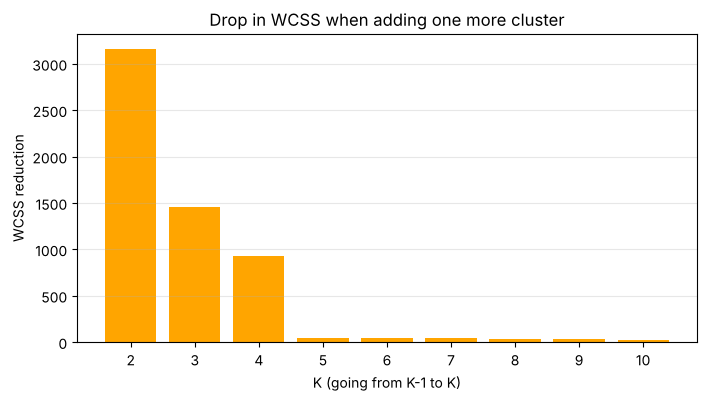

In [6]:
# Optional: show the drop in WCSS at each step to make the elbow clearer
drops = [wcss_values[i - 1] - wcss_values[i] for i in range(1, len(wcss_values))]

plt.figure(figsize=(8, 4))
plt.bar(range(2, 11), drops, color="orange")
plt.title("Drop in WCSS when adding one more cluster")
plt.xlabel("K (going from K-1 to K)")
plt.ylabel("WCSS reduction")
plt.xticks(range(2, 11))
plt.grid(axis="y", alpha=0.3)
plt.show()

## 5. Final clustering with the chosen K = 4

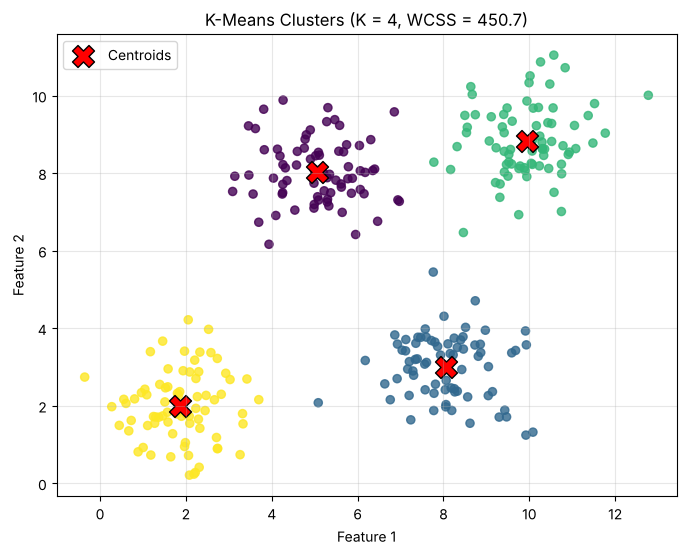

Cluster 0: 75 points, centroid = [5.06 8.04]
Cluster 1: 74 points, centroid = [8.06 3.01]
Cluster 2: 76 points, centroid = [9.94 8.83]
Cluster 3: 75 points, centroid = [1.87 1.98]


In [7]:
best_k = 4
labels, centroids, final_wcss = min(
    (kmeans(X, best_k) for _ in range(10)), key=lambda r: r[2]
)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis", s=35, alpha=0.8)
plt.scatter(centroids[:, 0], centroids[:, 1], c="red", marker="X",
            s=250, edgecolors="black", label="Centroids")
plt.title(f"K-Means Clusters (K = {best_k}, WCSS = {final_wcss:.1f})")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for i in range(best_k):
    print(f"Cluster {i}: {np.sum(labels == i)} points, centroid = {centroids[i].round(2)}")

## Summary
- Generated **300 points** with **2 features**.
- Implemented K-Means from scratch with NumPy.
- Computed **WCSS** for K = 1…10 and plotted the **Elbow curve** with the WCSS values labelled.
- The elbow appears at **K = 4**; the final clustering plot shows four well-separated groups with their centroids.